# Tutoring dialogue data: EDA, preprocessing and splits

This notebook prepares two tutoring dialogue datasets for later use. It reads the raw files in
`raw/`, explores them, puts both sources into one record format, cleans and annotates the dialogues,
splits them by problem and rebuilds the frozen candidate subset used for fine-tuning. Results go to `processed/` and `figures/`.

| Source | Content | Licence |
|---|---|---|
| SocraTeach_Multi | 10,273 maths word problems, each with 1 to 6 dialogues between a tutor and a simulated student | CC BY-NC 4.0 |
| MathDial | 2,861 dialogues between real teachers and simulated students, with a move label on each teacher turn | CC BY 4.0 |

The raw files are exports of the pinned HuggingFace revisions listed in `download_raw.py`. Run that
script once if `raw/` is empty. The notebook itself only reads local files and runs on a CPU.

In [1]:
import ast, gzip, hashlib, json, random, re, unicodedata
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import ks_2samp

SEED = 42
RAW = Path("raw")
PROCESSED = Path("processed")
FIGURES = Path("figures")
CAP_PER_PROBLEM = 3        # dialogues kept per problem in train and validation
VAL_FRACTION = 0.10        # share of problems held out for validation, per source
CANDIDATE_IDS = Path("candidate_v1_ids.json")   # frozen dialogue IDs of the fine-tuning subset (v1)

RAW_FILES = {
    "socrateach": RAW / "socrateach_multi_train.jsonl.gz",
    "mathdial_train": RAW / "mathdial_train.jsonl.gz",
    "mathdial_test": RAW / "mathdial_test.jsonl.gz",
}
missing = [str(p) for p in RAW_FILES.values() if not p.exists()]
assert not missing, f"Missing raw files {missing}. Run `python download_raw.py` once."

for d in [PROCESSED, FIGURES]:
    d.mkdir(exist_ok=True)
random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
STATS = {"config": dict(seed=SEED, cap_per_problem=CAP_PER_PROBLEM, val_fraction=VAL_FRACTION,
                        candidate_ids=str(CANDIDATE_IDS),
                        raw_files={k: str(v) for k, v in RAW_FILES.items()})}

## 1. Load the raw files

In [2]:
def read_jsonl_gz(path):
    with gzip.open(path, "rt", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

st_raw = read_jsonl_gz(RAW_FILES["socrateach"])
md_raw = {"train": read_jsonl_gz(RAW_FILES["mathdial_train"]), "test": read_jsonl_gz(RAW_FILES["mathdial_test"])}
print("SocraTeach rows:", len(st_raw), "| fields:", list(st_raw[0]))
print("MathDial rows:", {k: len(v) for k, v in md_raw.items()}, "| fields:", list(md_raw["train"][0]))

SocraTeach rows: 10273 | fields: ['id', 'question', 'analysis', 'answer', 'steps', 'dialogues']
MathDial rows: {'train': 2262, 'test': 599} | fields: ['qid', 'scenario', 'question', 'ground_truth', 'student_incorrect_solution', 'student_profile', 'teacher_described_confusion', 'self-correctness', 'self-typical-confusion', 'self-typical-interactions', 'conversation']


## 2. Raw EDA

In SocraTeach each row is one problem with its `question`, `answer`, worked `analysis`, solution
`steps` and a list of dialogues. Tutor turns are stored as `system` and student turns as `user`,
and each student turn has a `user_type` code. In MathDial each row is one dialogue, stored as a
single string in which turns are separated by `|EOM|` and teacher turns start with a move label in
brackets: probing, focus, telling or generic.

In [3]:
def as_list(x):
    return ast.literal_eval(x) if isinstance(x, str) else x

st_df = pd.DataFrame([dict(origin=r["id"].rsplit("_", 1)[0], n_dialogues=len(as_list(r["dialogues"]))) for r in st_raw])
md_df = pd.DataFrame([dict(split=s, question=r["question"], conversation=r["conversation"]) for s in md_raw for r in md_raw[s]])
md_df["teacher_moves"] = md_df.conversation.str.findall(r"Teacher: \((\w+)\)")

raw = {
    "socrateach_problems": len(st_df),
    "socrateach_dialogues": int(st_df.n_dialogues.sum()),
    "socrateach_problem_origin": st_df.origin.value_counts().to_dict(),
    "socrateach_dialogues_per_problem": st_df.n_dialogues.value_counts().sort_index().to_dict(),
    "mathdial_dialogues": md_df.split.value_counts().to_dict(),
    "mathdial_problems": md_df.groupby("split").question.nunique().to_dict(),
    "mathdial_test_problems_also_in_train": len(set(md_df[md_df.split == "test"].question) & set(md_df[md_df.split == "train"].question)),
    "mathdial_teacher_moves": dict(Counter(m for ms in md_df.teacher_moves for m in ms)),
}
STATS["raw"] = raw
for k, v in raw.items():
    print(f"{k}: {v}")

socrateach_problems: 10273
socrateach_dialogues: 35151
socrateach_problem_origin: {'GSM8K_train': 6798, 'MAWPS_train': 2300, 'GSM8K_test': 1175}
socrateach_dialogues_per_problem: {1: 1206, 2: 1532, 3: 2139, 4: 2600, 5: 2712, 6: 84}
mathdial_dialogues: {'train': 2262, 'test': 599}
mathdial_problems: {'test': 394, 'train': 1035}
mathdial_test_problems_also_in_train: 318
mathdial_teacher_moves: {'probing': 4252, 'generic': 4456, 'telling': 3091, 'focus': 6808}


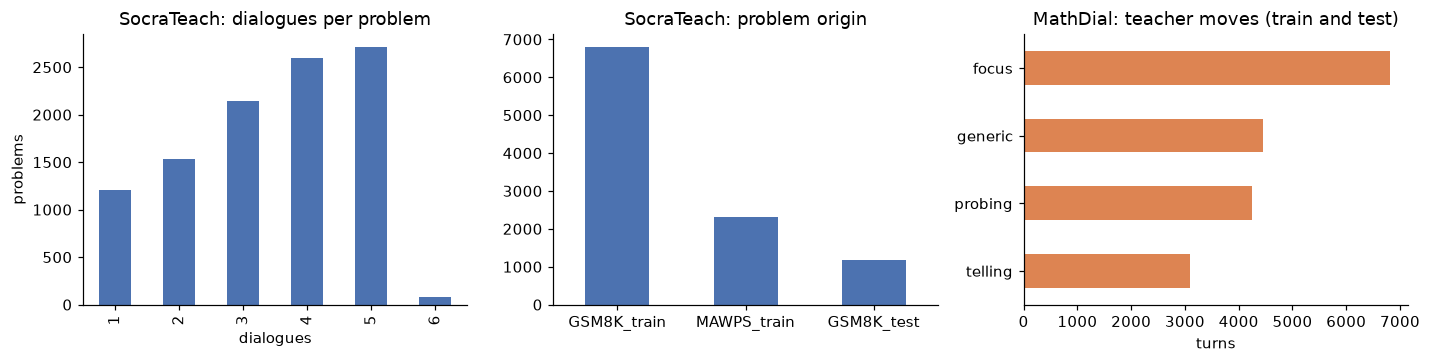

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
st_df.n_dialogues.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="SocraTeach: dialogues per problem", xlabel="dialogues", ylabel="problems")
st_df.origin.value_counts().plot.bar(ax=ax[1], color="#4C72B0")
ax[1].set(title="SocraTeach: problem origin", xlabel="")
ax[1].tick_params(axis="x", rotation=0)
pd.Series(raw["mathdial_teacher_moves"]).sort_values().plot.barh(ax=ax[2], color="#DD8452")
ax[2].set(title="MathDial: teacher moves (train and test)", xlabel="turns")
fig.tight_layout(); fig.savefig(FIGURES / "01_raw_overview.png"); plt.show()

What the raw data shows:

- SocraTeach has up to 6 dialogues for the same problem, so a split by dialogue would put the same problem in train and test.
- SocraTeach takes problems from GSM8K train, GSM8K test and MAWPS. MathDial is also built on GSM8K, so the two sources share problems.
- Most MathDial test problems also appear in MathDial train.
- About a sixth of MathDial teacher turns are "telling", where the teacher gives the answer or the next step outright.

## 3. One record format for both sources

In [5]:
def norm_text(s):
    s = unicodedata.normalize("NFKC", s or "").lower()
    s = re.sub(r"[^a-z0-9.%$ ]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def problem_id(question):
    return "p_" + hashlib.sha1(norm_text(question).encode()).hexdigest()[:12]

def clean_msg(s):
    return re.sub(r"\s+", " ", (s or "")).strip()

def merge_same_role(messages):
    out = []
    for m in messages:
        if out and out[-1]["role"] == m["role"]:
            out[-1]["content"] += "\n" + m["content"]
            out[-1]["move"] = out[-1].get("move") or m.get("move")
        else:
            out.append(dict(m))
    return out

records = []
for r in st_raw:
    for d in as_list(r["dialogues"]):
        msgs = []
        for t in d["turns"]:
            if clean_msg(t.get("system")):
                msgs.append(dict(role="tutor", content=clean_msg(t["system"]), move=None))
            if clean_msg(t.get("user")):
                msgs.append(dict(role="student", content=clean_msg(t["user"]), move=None,
                                 student_type=(t.get("user_type") or "").strip("()] ") or None))
        records.append(dict(dialogue_id=d["dialogue_id"], source="socrateach", official_split="train",
                            problem_origin=r["id"].rsplit("_", 1)[0], question=r["question"].strip(),
                            reference_answer=str(r["answer"]).strip(), reference_solution=(r["analysis"] or "").strip(),
                            student_attempt=None, messages=merge_same_role(msgs)))

for split in md_raw:
    for i, r in enumerate(md_raw[split]):
        msgs = []
        for part in r["conversation"].split("|EOM|"):
            speaker, _, text = part.partition(":")
            if speaker.strip() == "Teacher":
                m = re.match(r"\s*\((\w+)\)(.*)", text, re.S)
                move, text = (m.group(1), m.group(2)) if m else (None, text)
                role = "tutor"
            else:
                move, role = None, "student"
            if clean_msg(text):
                msgs.append(dict(role=role, content=clean_msg(text), move=move))
        records.append(dict(dialogue_id=f"mathdial_{split}_{r['qid']}_{i}", source="mathdial", official_split=split,
                            problem_origin="mathdial", question=r["question"].strip(),
                            reference_answer=r["ground_truth"].strip().splitlines()[-1].strip(),   # the last line holds the final answer
                            reference_solution=r["ground_truth"].strip(),
                            student_attempt=r["student_incorrect_solution"].strip(), messages=merge_same_role(msgs)))

for rec in records:
    rec["problem_id"] = problem_id(rec["question"])
print(len(records), Counter(r["source"] for r in records))

38012 Counter({'socrateach': 35151, 'mathdial': 2861})


In [6]:
# Problems that appear in both sources
pids = defaultdict(set)
for r in records:
    pids[(r["source"], r["official_split"])].add(r["problem_id"])
overlap = {
    "socrateach & mathdial_train": len(pids[("socrateach", "train")] & pids[("mathdial", "train")]),
    "socrateach & mathdial_test": len(pids[("socrateach", "train")] & pids[("mathdial", "test")]),
    "mathdial_train & mathdial_test": len(pids[("mathdial", "train")] & pids[("mathdial", "test")]),
}
STATS["raw_problem_overlap"] = overlap
overlap

{'socrateach & mathdial_train': 1006,
 'socrateach & mathdial_test': 383,
 'mathdial_train & mathdial_test': 318}

## 4. Cleaning and annotation

Cleaning drops empty messages, merges consecutive messages from the same speaker, removes trailing
student messages, drops dialogues that lack either a tutor or a student message, and removes exact
duplicates of the same problem.

Each tutor message also gets a `leaks_answer` flag. It is true when the tutor states the final
answer before the student has said it. MathDial tutor messages keep their move label. Both are
annotations only; no dialogue is removed because of them.

In [7]:
NUM = re.compile(r"(?<![\d./])-?\d[\d,]*(?:\.\d+)?(?!\d|\.\d|/)")   # skips parts of fractions such as 1/3

def numbers(text):
    return {n.replace(",", "").rstrip("0").rstrip(".") if "." in n else n.replace(",", "") for n in NUM.findall(text)}

def answer_key(rec):
    found = numbers(rec["reference_answer"])
    key = found.pop() if len(found) == 1 else None
    return None if key in numbers(rec["question"]) else key   # a number already given in the problem cannot leak

def flag_leaks(rec):
    # ponytail: covers single-number answers only; textual answers are not checked
    key, said = answer_key(rec), False
    for m in rec["messages"]:
        if m["role"] == "student":
            said = said or (key is not None and key in numbers(m["content"]))
        else:
            m["leaks_answer"] = key is not None and not said and key in numbers(m["content"])

drops, seen, cleaned = Counter(), set(), []
for rec in records:
    msgs = rec["messages"]
    while msgs and msgs[-1]["role"] == "student":
        msgs.pop()
    if not {"tutor", "student"} <= {m["role"] for m in msgs}:
        drops["too_short"] += 1; continue
    key = (rec["problem_id"], json.dumps([(m["role"], norm_text(m["content"])) for m in msgs]))
    if key in seen:
        drops["duplicate"] += 1; continue
    seen.add(key)
    flag_leaks(rec)
    rec["n_messages"] = len(msgs)
    rec["n_words"] = sum(len(m["content"].split()) for m in msgs)
    cleaned.append(rec)

STATS["cleaning_drops"] = dict(drops)
print("kept", len(cleaned), "dropped", dict(drops))

kept 38012 dropped {}


## 5. Split by problem

The test set is every MathDial official-test dialogue. Any problem that appears in it is removed
from the remaining data in both sources, so no test problem is seen during training or validation.
Validation then takes `VAL_FRACTION` of the remaining problems from each source. Train and
validation keep at most `CAP_PER_PROBLEM` dialogues per problem from each source, so on a problem the two
sources share, SocraTeach's repeats cannot push out the scarcer MathDial dialogues.

In [8]:
test = [r for r in cleaned if r["source"] == "mathdial" and r["official_split"] == "test"]
test_ids, test_pids = {r["dialogue_id"] for r in test}, {r["problem_id"] for r in test}
pool = [r for r in cleaned if r["dialogue_id"] not in test_ids]
removed_for_test = [r for r in pool if r["problem_id"] in test_pids]
pool = [r for r in pool if r["problem_id"] not in test_pids]

rng = random.Random(SEED)
val_pids = set()
for src in ["mathdial", "socrateach"]:
    src_pids = sorted({r["problem_id"] for r in pool if r["source"] == src} - val_pids)
    val_pids |= set(rng.sample(src_pids, round(len(src_pids) * VAL_FRACTION)))

def cap(rows):
    # Capped per problem AND source: a shared GSM8K problem keeps up to 3 dialogues from each source,
    # so SocraTeach repeats never crowd out the scarcer real-teacher MathDial dialogues.
    by_pid = defaultdict(list)
    for r in rows:
        by_pid[(r["problem_id"], r["source"])].append(r)
    out = []
    for pid in sorted(by_pid):
        group = sorted(by_pid[pid], key=lambda r: r["dialogue_id"])
        rng.shuffle(group)
        out += group[:CAP_PER_PROBLEM]
    return out

val = cap([r for r in pool if r["problem_id"] in val_pids])
train = cap([r for r in pool if r["problem_id"] not in val_pids])
splits = {"train": train, "val": val, "test": test}

for a in splits:      # no problem and no dialogue may appear in two splits
    for b in splits:
        if a < b:
            assert not ({r["problem_id"] for r in splits[a]} & {r["problem_id"] for r in splits[b]}), (a, b)
            assert not ({r["dialogue_id"] for r in splits[a]} & {r["dialogue_id"] for r in splits[b]}), (a, b)
print("no problem or dialogue is shared between splits")

STATS["split"] = {
    "removed_because_problem_in_test": dict(Counter(r["source"] for r in removed_for_test)),
    "dropped_by_cap": len(pool) - len(train) - len(val),
    **{name: {"dialogues": len(rows), "problems": len({r["problem_id"] for r in rows}),
              "by_source": dict(Counter(r["source"] for r in rows))} for name, rows in splits.items()},
}
pd.DataFrame({k: {**{f"{s} dialogues": STATS["split"][k]["by_source"].get(s, 0) for s in ["mathdial", "socrateach"]},
                  "problems": STATS["split"][k]["problems"]} for k in splits}).T

no problem or dialogue is shared between splits


,mathdial dialogues,socrateach dialogues,problems
train,1302,22574,8661
val,311,2682,1032
test,599,0,394


## 6. Candidate subset

The candidate subset is the small train and validation set used for the baseline and fine-tuning
runs. It is frozen at version 1: 1,000 SocraTeach and 767 MathDial training dialogues, plus 100 of
each source for validation. Version 1 was drawn (stratified by word-count quartile) before the cap
was changed to count each source separately. The fine-tuning runs had already used it, so it stays
fixed and `candidate_v1_ids.json` lists its dialogue IDs.

The notebook rebuilds the subset from those IDs. Each dialogue must come from a train problem
(or, for validation, a val problem), so the subset never touches validation or test problems. A few
SocraTeach dialogues in v1 were dropped by the new cap, so the subset is drawn from the uncapped pool
of each split's problems. Section 7 compares the subset with the full train split.

In [9]:
frozen = json.load(open(CANDIDATE_IDS))
by_id = {r["dialogue_id"]: r for r in pool}
cand_train = [by_id[i] for i in frozen["train"]]
cand_val = [by_id[i] for i in frozen["val"]]
train_pids, val_pids_kept = {r["problem_id"] for r in train}, {r["problem_id"] for r in val}
assert all(r["problem_id"] in train_pids for r in cand_train), "candidate_train uses a non-train problem"
assert all(r["problem_id"] in val_pids_kept for r in cand_val), "candidate_val uses a non-val problem"
STATS["candidate"] = {"train": dict(Counter(r["source"] for r in cand_train)), "val": dict(Counter(r["source"] for r in cand_val))}
STATS["candidate"]

{'train': {'mathdial': 767, 'socrateach': 1000},
 'val': {'mathdial': 100, 'socrateach': 100}}

## 7. EDA after processing

In [10]:
def frame(rows, name):
    out = []
    for r in rows:
        tutor = [m for m in r["messages"] if m["role"] == "tutor"]
        out.append(dict(split=name, source=r["source"], words=r["n_words"], messages=r["n_messages"],
                        leak_share=sum(m["leaks_answer"] for m in tutor) / len(tutor),
                        telling_share=sum(m.get("move") == "telling" for m in tutor) / len(tutor)))
    return pd.DataFrame(out)

eda = pd.concat([frame(train, "train"), frame(val, "val"), frame(test, "test"),
                 frame(cand_train, "candidate_train"), frame(cand_val, "candidate_val")])
summary = eda.groupby(["split", "source"]).agg(dialogues=("words", "size"), words_median=("words", "median"),
                                               words_p95=("words", lambda s: s.quantile(.95)), messages_median=("messages", "median"),
                                               leak_share=("leak_share", "mean"), telling_share=("telling_share", "mean")).round(3)
STATS["eda_summary"] = summary.reset_index().to_dict(orient="records")
summary

dialogues  words_median  words_p95  \
split           source                                           
candidate_train mathdial          767         281.0     691.00   
                socrateach       1000         230.0     391.10   
candidate_val   mathdial          100         267.5     586.35   
                socrateach        100         233.5     395.35   
test            mathdial          599         265.0     603.10   
train           mathdial         1302         274.0     688.95   
                socrateach      22574         232.0     390.00   
val             mathdial          311         254.0     644.50   
                socrateach       2682         234.0     393.00   

                            messages_median  leak_share  telling_share  
split           source                                                  
candidate_train mathdial               11.0       0.016          0.152  
                socrateach              9.0       0.003          0.000  
candidate_val   mathdial               11.0       0.017          0.203  
                socrateach             10.0       0.002          0.000  
test            mathdial               11.0       0.021          0.158  
train           mathdial               11.0       0.017          0.154  
                socrateach              9.0       0.003          0.000  
val             mathdial               11.0       0.018          0.174  
                socrateach              9.0       0.004          0.000

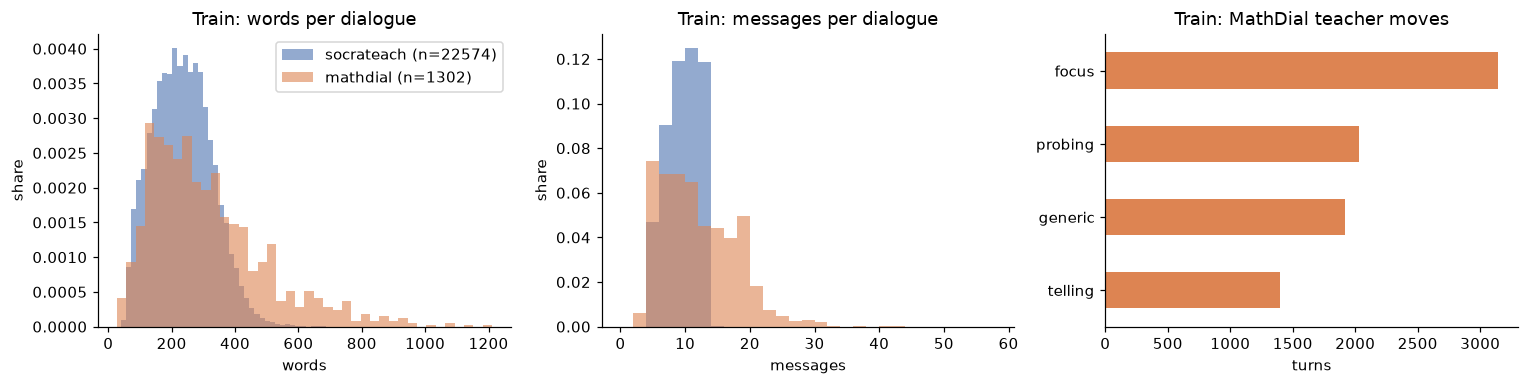

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for src, color in [("socrateach", "#4C72B0"), ("mathdial", "#DD8452")]:
    s = eda[(eda.split == "train") & (eda.source == src)]
    ax[0].hist(s.words, bins=40, density=True, alpha=.6, label=f"{src} (n={len(s)})", color=color)
    ax[1].hist(s.messages, bins=range(0, 60, 2), density=True, alpha=.6, label=src, color=color)
ax[0].set(title="Train: words per dialogue", xlabel="words", ylabel="share"); ax[0].legend()
ax[1].set(title="Train: messages per dialogue", xlabel="messages", ylabel="share")
moves = Counter(m.get("move") for r in train if r["source"] == "mathdial" for m in r["messages"] if m["role"] == "tutor")
pd.Series({k: v for k, v in moves.items() if k}).sort_values().plot.barh(ax=ax[2], color="#DD8452")
ax[2].set(title="Train: MathDial teacher moves", xlabel="turns")
fig.tight_layout(); fig.savefig(FIGURES / "02_train_distributions.png"); plt.show()

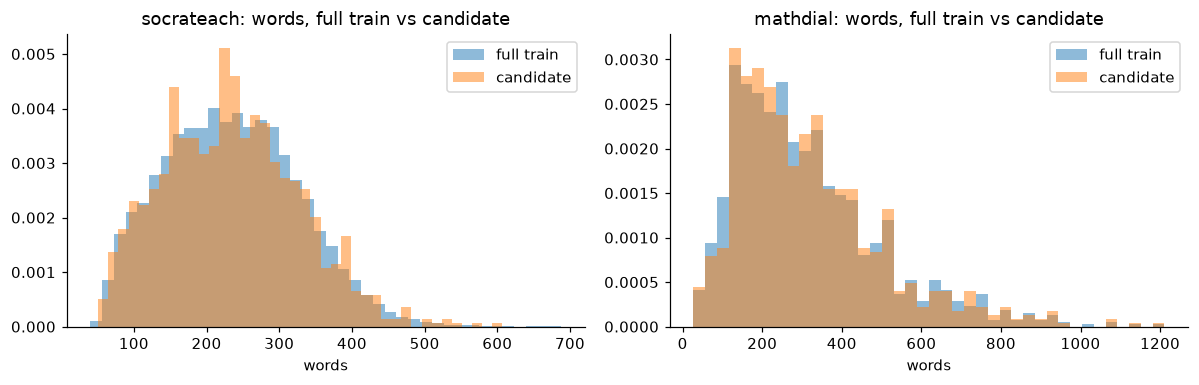

,source,feature,full_mean,subset_mean,ks_stat,p_value,subset_is_whole_source
0,socrateach,words,234.850,234.895,0.018,0.892,False
1,socrateach,messages,9.713,9.704,0.007,1.000,False
2,socrateach,leak_share,0.003,0.003,0.005,1.000,False
3,socrateach,telling_share,0.000,0.000,0.000,1.000,False
4,mathdial,words,314.157,317.344,0.022,0.966,False
5,mathdial,messages,12.035,12.108,0.009,1.000,False
6,mathdial,leak_share,0.017,0.016,0.007,1.000,False
7,mathdial,telling_share,0.154,0.152,0.014,1.000,False


In [12]:
# Candidate subset against the full train split, per source, with a two-sample KS test
rep = []
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for k, src in enumerate(["socrateach", "mathdial"]):
    full = eda[(eda.split == "train") & (eda.source == src)]
    sub = eda[(eda.split == "candidate_train") & (eda.source == src)]
    for col in ["words", "messages", "leak_share", "telling_share"]:
        ks = ks_2samp(full[col], sub[col])
        rep.append(dict(source=src, feature=col, full_mean=round(full[col].mean(), 3), subset_mean=round(sub[col].mean(), 3),
                        ks_stat=round(ks.statistic, 3), p_value=round(ks.pvalue, 3), subset_is_whole_source=len(sub) == len(full)))
    ax[k].hist(full.words, bins=40, density=True, alpha=.5, label="full train")
    ax[k].hist(sub.words, bins=40, density=True, alpha=.5, label="candidate")
    ax[k].set(title=f"{src}: words, full train vs candidate", xlabel="words"); ax[k].legend()
fig.tight_layout(); fig.savefig(FIGURES / "03_candidate_vs_full.png"); plt.show()
rep = pd.DataFrame(rep); STATS["candidate_representativeness"] = rep.to_dict(orient="records")
rep

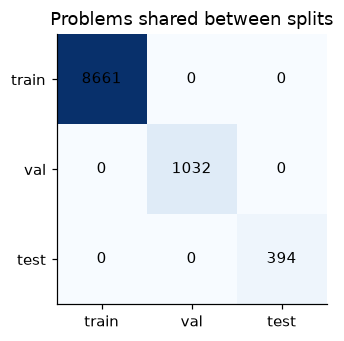

,train,val,test
train,8661,0,0
val,0,1032,0
test,0,0,394


In [13]:
names = list(splits)   # problems shared between splits; everything off the diagonal must be zero
mat = pd.DataFrame([[len({r["problem_id"] for r in splits[a]} & {r["problem_id"] for r in splits[b]}) for b in names] for a in names],
                   index=names, columns=names)
fig, ax = plt.subplots(figsize=(4, 3.2))
ax.imshow(mat.values, cmap="Blues")
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, mat.values[i, j], ha="center", va="center")
ax.set_xticks(range(len(names)), names); ax.set_yticks(range(len(names)), names)
ax.set_title("Problems shared between splits")
fig.tight_layout(); fig.savefig(FIGURES / "04_split_overlap.png"); plt.show()
mat

In [14]:
for r in [next(x for x in cand_train if x["source"] == s) for s in ["socrateach", "mathdial"]]:
    print("=" * 100, f"\n{r['source']} | {r['dialogue_id']} | {r['problem_id']} | answer: {r['reference_answer']}\nQ: {r['question'][:250]}")
    for m in r["messages"][:6]:
        tags = [t for t in [m.get("move"), "LEAK" if m.get("leaks_answer") else None] if t]
        print(f"  {m['role']}{' ' + str(tags) if tags else ''}: {m['content'][:220]}")

socrateach | GSM8K_train_1096_4 | p_4c772a643a63 | answer: 180
Q: Rory has 30 more jellybeans than her sister Gigi who has 15 jellybeans.  Lorelai has already eaten three times the number of jellybeans that both girls have.  How many jellybeans has Lorelai eaten?
  tutor: How many jellybeans does Rory have?
  student: Rory has 45 jellybeans, because Gigi has 15 and Rory has 30 more.
  tutor: That's right! Now, can you tell me how many jellybeans do Rory and Gigi have together?
  student: If you add Rory's 45 jellybeans to Gigi's 15 jellybeans, they have a total of 60 jellybeans together.
  tutor: Correct! Now, since Lorelai has eaten three times the number of jellybeans that both girls have, can you tell me how many jellybeans has Lorelai eaten?
  student: Lorelai has eaten 180 jellybeans, because she ate three times the amount that Rory and Gigi have together, which is 60. So 60 times 3 equals 180.
mathdial | mathdial_train_5000191_1614 | p_4088f9eb31f8 | answer: 38400
Q: Jerry needs 

## 8. Save

Each file in `processed/` is gzipped JSON Lines with one dialogue per line. A record has
`dialogue_id`, `problem_id`, `source`, `official_split`, `problem_origin`, `question`,
`reference_answer`, `reference_solution`, `student_attempt` (MathDial only), `n_messages`, `n_words`
and `messages`. Each message has `role` (tutor or student), `content`, `move` (MathDial teacher
turns), `leaks_answer` (tutor turns) and `student_type` (SocraTeach student turns).

In [15]:
for name, rows in {"train": train, "val": val, "test": test, "candidate_train": cand_train, "candidate_val": cand_val}.items():
    with gzip.open(PROCESSED / f"{name}.jsonl.gz", "wt", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
json.dump({name: sorted({r["problem_id"] for r in rows}) for name, rows in splits.items()},
          open(PROCESSED / "split_problem_ids.json", "w"), indent=0)
json.dump(STATS, open(PROCESSED / "stats.json", "w"), indent=1, default=str)
print({p.name: p.stat().st_size for p in sorted(PROCESSED.iterdir())})

{'candidate_train.jsonl.gz': 1034575, 'candidate_val.jsonl.gz': 119161, 'split_problem_ids.json': 181604, 'stats.json': 5099, 'test.jsonl.gz': 376629, 'train.jsonl.gz': 9960551, 'val.jsonl.gz': 1258387}


## Limitations

- Neither source contains real learner data. SocraTeach students are simulated by a language model, and MathDial pairs real teachers with simulated students.
- SocraTeach includes GSM8K test problems, so GSM8K test accuracy is not a clean measure for anything built on this data.
- `leaks_answer` checks only single-number final answers that are not already in the problem text.
- Keeping the test set unseen removes every MathDial train dialogue whose problem is also in the test set, which shrinks the MathDial share of train considerably. `STATS["split"]` records how many.
- SocraTeach_Multi is licensed CC BY-NC 4.0 (non-commercial use with attribution) and MathDial CC BY 4.0. Both need citing.